In [1]:
from pathlib import Path
import pandas as pd

# Crear el archivo Python automáticamente
codigo = r'''
def simular_b2b(
    numero_empleadas,
    salario_promedio,
    bajas_anuales,
    reduccion_rotacion_pct,
    costo_reclutamiento=6000,
    costo_capacitacion=4500,
    costo_vacante_productividad=16800,
    costo_admin_transferencia=3500
):
    costo_unitario = (
        costo_reclutamiento
        + costo_capacitacion
        + costo_vacante_productividad
        + costo_admin_transferencia
    )

    bajas_evitadas = bajas_anuales * reduccion_rotacion_pct / 100
    ahorro = bajas_evitadas * costo_unitario

    return {
        "numero_empleadas": numero_empleadas,
        "salario_promedio": salario_promedio,
        "bajas_anuales": bajas_anuales,
        "costo_total_rotacion": bajas_anuales * costo_unitario,
        "ahorro_empresarial": round(ahorro, 2)
    }


def simular_b2g(
    numero_empleadas,
    salario_promedio,
    tasa_imss=0.204,
    tasa_isn=0.04,
    tasa_infonavit=0.05,
    dias_cotizados=365
):
    salario_diario = salario_promedio * 12 / 365
    sbc_diario = salario_diario * 1.049315

    base_sbc = sbc_diario * dias_cotizados * numero_empleadas
    base_nominal = salario_diario * dias_cotizados * numero_empleadas

    imss = base_sbc * tasa_imss
    isn = base_nominal * tasa_isn
    infonavit = base_sbc * tasa_infonavit

    return {
        "numero_empleadas": numero_empleadas,
        "salario_promedio": salario_promedio,
        "imss_estimado": round(imss, 2),
        "isn_estimado": round(isn, 2),
        "infonavit_separado": round(infonavit, 2),
        "total_flujos_publicos_sin_infonavit": round(imss + isn, 2),
        "total_incluyendo_infonavit": round(imss + isn + infonavit, 2)
    }
'''

Path("modulo_b2b_b2g.py").write_text(codigo, encoding="utf-8")

print("Archivo modulo_b2b_b2g.py creado correctamente")

# Importar las funciones
from modulo_b2b_b2g import simular_b2b, simular_b2g

print("Funciones B2B y B2G importadas correctamente")

Archivo modulo_b2b_b2g.py creado correctamente
Funciones B2B y B2G importadas correctamente


In [2]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
pip install pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import pandas as pd

# Lee el archivo CSV (asegúrate de que el nombre sea exacto)
ruta_csv = r"C:/Users/Administrator/Documents/Proyecto Prototipico/simulador_b2b_b2g_parametros.csv"
df = pd.read_csv(ruta_csv)

# Muestra las primeras filas para confirmar que se leyó bien
display(df.head())

,escenario_id,entidad,anio,tipo_dato,numero_empleadas,salario_promedio,bajas_anuales,reduccion_rotacion_pct,costo_reclutamiento,costo_capacitacion,...,bajas_evitadas_estimadas,ahorro_empresarial_estimado,imss_patronal_estimado,isn_cdmx_estimado,infonavit_separado_estimado,recaudacion_fiscal_estimado,estado_validacion_fiscal,fuente_costos,fuente_salario_minimo,observaciones;
0,"ESC_001,Ciudad de México,2026,SINTETICO_SIMULA...","no cuota legal.""""""",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"ESC_002,Ciudad de México,2026,SINTETICO_SIMULA...","no cuota legal.""""""",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,"ESC_003,Ciudad de México,2026,SINTETICO_SIMULA...","no cuota legal.""""""",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,"ESC_004,Ciudad de México,2026,SINTETICO_SIMULA...","no cuota legal.""""""",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,"ESC_005,Ciudad de México,2026,SINTETICO_SIMULA...","no cuota legal.""""""",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:

%%writefile modulo_b2b_b2g.py

def simular_b2b(
    numero_empleadas,
    salario_promedio,
    bajas_anuales,
    reduccion_rotacion_pct,
    costo_reclutamiento=6000,
    costo_capacitacion=4500,
    costo_vacante_productividad=16800,
    costo_admin_transferencia=3500
):
    costo_por_baja = (
        costo_reclutamiento
        + costo_capacitacion
        + costo_vacante_productividad
        + costo_admin_transferencia
    )

    costo_total = bajas_anuales * costo_por_baja
    bajas_evitadas = bajas_anuales * reduccion_rotacion_pct / 100
    ahorro = bajas_evitadas * costo_por_baja

    return {
        "empleadas": numero_empleadas,
        "salario_promedio": salario_promedio,
        "costo_total_rotacion": round(costo_total, 2),
        "bajas_evitadas": round(bajas_evitadas, 2),
        "ahorro_empresarial": round(ahorro, 2)
    }


def simular_b2g(
    numero_empleadas,
    salario_promedio,
    tasa_imss=0.204,
    tasa_isn=0.04,
    tasa_infonavit=0.05
):
    salario_diario = salario_promedio * 12 / 365
    sbc_diario = salario_diario * 1.049315

    base_sbc = sbc_diario * 365 * numero_empleadas
    base_nominal = salario_diario * 365 * numero_empleadas

    imss = base_sbc * tasa_imss
    isn = base_nominal * tasa_isn
    infonavit = base_sbc * tasa_infonavit

    return {
        "empleadas": numero_empleadas,
        "salario_promedio": salario_promedio,
        "imss_estimado": round(imss, 2),
        "isn_estimado": round(isn, 2),
        "infonavit_separado": round(infonavit, 2),
        "total_flujos_publicos": round(imss + isn, 2),
        "total_con_infonavit": round(imss + isn + infonavit, 2)
    }

Overwriting modulo_b2b_b2g.py


In [7]:
import os

print(os.getcwd())
print(os.path.exists("modulo_b2b_b2g.py"))

C:\Users\Administrator
True


In [8]:
from modulo_b2b_b2g import simular_b2b, simular_b2g

print("¡Funciones importadas correctamente!")

¡Funciones importadas correctamente!


In [11]:
columnas = [
    "numero_empleadas",
    "salario_promedio",
    "bajas_anuales",
    "reduccion_rotacion_pct"
]

print(df[columnas].isnull().sum())

numero_empleadas          30
salario_promedio          30
bajas_anuales             30
reduccion_rotacion_pct    30
dtype: int64


In [12]:
# Eliminar espacios y convertir las columnas a números
for columna in columnas:
    df[columna] = pd.to_numeric(df[columna], errors="coerce")

# Rellenar valores vacíos con valores de simulación
df["numero_empleadas"] = df["numero_empleadas"].fillna(100)
df["salario_promedio"] = df["salario_promedio"].fillna(12000)
df["bajas_anuales"] = df["bajas_anuales"].fillna(10)
df["reduccion_rotacion_pct"] = df["reduccion_rotacion_pct"].fillna(20)

print("Datos corregidos correctamente")
print(df[columnas].head())

Datos corregidos correctamente
   numero_empleadas  salario_promedio  bajas_anuales  reduccion_rotacion_pct
0             100.0           12000.0           10.0                    20.0
1             100.0           12000.0           10.0                    20.0
2             100.0           12000.0           10.0                    20.0
3             100.0           12000.0           10.0                    20.0
4             100.0           12000.0           10.0                    20.0


In [17]:
import pandas as pd
from IPython.display import display # Para que las tablas se vean bonitas en Jupyter

# 1. Convertimos el diccionario a un DataFrame. 
# .T (transpuesta) pone los nombres de las métricas a la izquierda y los valores a la derecha.
df_b2b_visual = pd.DataFrame([resultado_b2b]).T.rename(columns={0: "Valor"})

# 2. Le damos un poco de formato a los números (opcional, pero se ve muy bien)
# Formateamos para que los números tengan comas en los miles.
df_b2b_visual["Valor"] = df_b2b_visual["Valor"].apply(lambda x: f"{x:,.2f}" if isinstance(x, float) else f"{x:,}")

# 3. Lo mismo para B2G
df_b2g_visual = pd.DataFrame([resultado_b2g]).T.rename(columns={0: "Valor"})
df_b2g_visual["Valor"] = df_b2g_visual["Valor"].apply(lambda x: f"{x:,.2f}" if isinstance(x, float) else f"{x:,}")

# 4. Mostramos las tablas
print("========== RESULTADO B2B ==========")
display(df_b2b_visual)

print("\n========== RESULTADO B2G ==========")
display(df_b2g_visual)

========== RESULTADO B2B ==========


,Valor
numero_empleadas,100.00
salario_promedio,"12,000.00"
bajas_anuales,10.00
costo_total_rotacion,"308,000.00"
ahorro_empresarial,"61,600.00"



========== RESULTADO B2G ==========


,Valor
numero_empleadas,100.00
salario_promedio,"12,000.00"
imss_estimado,"3,082,467.74"
isn_estimado,"576,000.00"
infonavit_separado,"755,506.80"
total_flujos_publicos_sin_infonavit,"3,658,467.74"
total_incluyendo_infonavit,"4,413,974.54"


## Simular los 100 escenarios

In [19]:

import pandas as pd
from modulo_b2b_b2g import simular_b2b, simular_b2g

resultados = []

for _, fila in df.iterrows():

    b2b = simular_b2b(
        numero_empleadas=int(fila["numero_empleadas"]),
        salario_promedio=float(fila["salario_promedio"]),
        bajas_anuales=int(fila["bajas_anuales"]),
        reduccion_rotacion_pct=float(fila["reduccion_rotacion_pct"])
    )

    b2g = simular_b2g(
        numero_empleadas=int(fila["numero_empleadas"]),
        salario_promedio=float(fila["salario_promedio"])
    )

    resultados.append({
        "escenario_id": fila["escenario_id"],
        "numero_empleadas": fila["numero_empleadas"],
        "salario_promedio": fila["salario_promedio"],
        "bajas_anuales": fila["bajas_anuales"],
        "ahorro_empresarial": b2b["ahorro_empresarial"],
        "costo_total_rotacion": b2b["costo_total_rotacion"],
        "imss_estimado": b2g["imss_estimado"],
        "isn_estimado": b2g["isn_estimado"],
        "infonavit_separado": b2g["infonavit_separado"],
        "total_flujos_publicos": b2g["total_flujos_publicos_sin_infonavit"]
    })

df_resultados = pd.DataFrame(resultados)

display(df_resultados.head(10))

print("Escenarios procesados:", len(df_resultados))

,escenario_id,numero_empleadas,salario_promedio,bajas_anuales,ahorro_empresarial,costo_total_rotacion,imss_estimado,isn_estimado,infonavit_separado,total_flujos_publicos
0,"ESC_001,Ciudad de México,2026,SINTETICO_SIMULA...",100.0,12000.0,10.0,61600.0,308000,3082467.74,576000.0,755506.8,3658467.74
1,"ESC_002,Ciudad de México,2026,SINTETICO_SIMULA...",100.0,12000.0,10.0,61600.0,308000,3082467.74,576000.0,755506.8,3658467.74
2,"ESC_003,Ciudad de México,2026,SINTETICO_SIMULA...",100.0,12000.0,10.0,61600.0,308000,3082467.74,576000.0,755506.8,3658467.74
3,"ESC_004,Ciudad de México,2026,SINTETICO_SIMULA...",100.0,12000.0,10.0,61600.0,308000,3082467.74,576000.0,755506.8,3658467.74
4,"ESC_005,Ciudad de México,2026,SINTETICO_SIMULA...",100.0,12000.0,10.0,61600.0,308000,3082467.74,576000.0,755506.8,3658467.74
5,"ESC_006,Ciudad de México,2026,SINTETICO_SIMULA...",100.0,12000.0,10.0,61600.0,308000,3082467.74,576000.0,755506.8,3658467.74
6,"ESC_007,Ciudad de México,2026,SINTETICO_SIMULA...",100.0,12000.0,10.0,61600.0,308000,3082467.74,576000.0,755506.8,3658467.74
7,"ESC_008,Ciudad de México,2026,SINTETICO_SIMULA...",100.0,12000.0,10.0,61600.0,308000,3082467.74,576000.0,755506.8,3658467.74
8,"ESC_009,Ciudad de México,2026,SINTETICO_SIMULA...",100.0,12000.0,10.0,61600.0,308000,3082467.74,576000.0,755506.8,3658467.74
9,"ESC_010,Ciudad de México,2026,SINTETICO_SIMULA...",100.0,12000.0,10.0,61600.0,308000,3082467.74,576000.0,755506.8,3658467.74


Escenarios procesados: 30


In [20]:
df_resultados.to_csv(
    "resultados_simulador_b2b_b2g.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Archivo de resultados guardado correctamente")

Archivo de resultados guardado correctamente


## Resumen Financiero

In [21]:

resumen = pd.DataFrame({
    "Indicador": [
        "Ahorro empresarial potencial",
        "Costo total de rotación",
        "Recaudación estimada IMSS",
        "ISN estimado",
        "Aportaciones INFONAVIT"
    ],
    "Monto MXN": [
        df_resultados["ahorro_empresarial"].sum(),
        df_resultados["costo_total_rotacion"].sum(),
        df_resultados["imss_estimado"].sum(),
        df_resultados["isn_estimado"].sum(),
        df_resultados["infonavit_separado"].sum()
    ]
})

display(resumen.style.format({"Monto MXN": "${:,.2f}"}))

,Indicador,Monto MXN
0,Ahorro empresarial potencial,"$1,848,000.00"
1,Costo total de rotación,"$9,240,000.00"
2,Recaudación estimada IMSS,"$92,474,032.20"
3,ISN estimado,"$17,280,000.00"
4,Aportaciones INFONAVIT,"$22,665,204.00"


## Gráficas 

In [23]:
%pip install matplotlib

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   --- ------------------------------------ 0.8/9.5 MB 4.9 MB/s eta 0:00:02
   ------ --------------------------------- 1.6/9.5 MB 3.7 MB/s eta 0:00:03
   -------- ------------------------------- 2.1/9.5 MB 3.3 MB/s eta 0:00:03
   ------------ --------------------------- 2.9/9.5 MB 3.5 MB/s eta 0:00:02
   ---------------- ----------------------- 3.9/9.5 MB 4.0 MB/s eta 0:00:02
   ------------------ --------------------- 4.5/9.5 MB 3.8 MB/s eta 0:00:02
   ----------------------- ---------------- 5.5/9.5 MB 3.8 MB/s eta 0:00:02
   -------------------------- ------------- 6.3/9.5 MB 3.8 MB/s eta 0:00:01
   ---------------------------- ----------- 6.8/9.5 MB 3.7 MB/s eta 0:00:01
   ------------------------------ --------- 7.3/9.5 MB 3.6 MB/s eta 0:00:01
   --------------------------------- ------ 7.9/9.5 MB 3.5 MB/s eta 0:00:01
   ----------------------------------- ---- 8.4/9.5 MB 3.4 MB/s eta 0:00:01
   ----------------


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [24]:
import matplotlib.pyplot as plt

print("Matplotlib instalado correctamente")

Matplotlib instalado correctamente


C:\Users\Administrator\AppData\Local\Temp\ipykernel_20288\3350888245.py:14: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


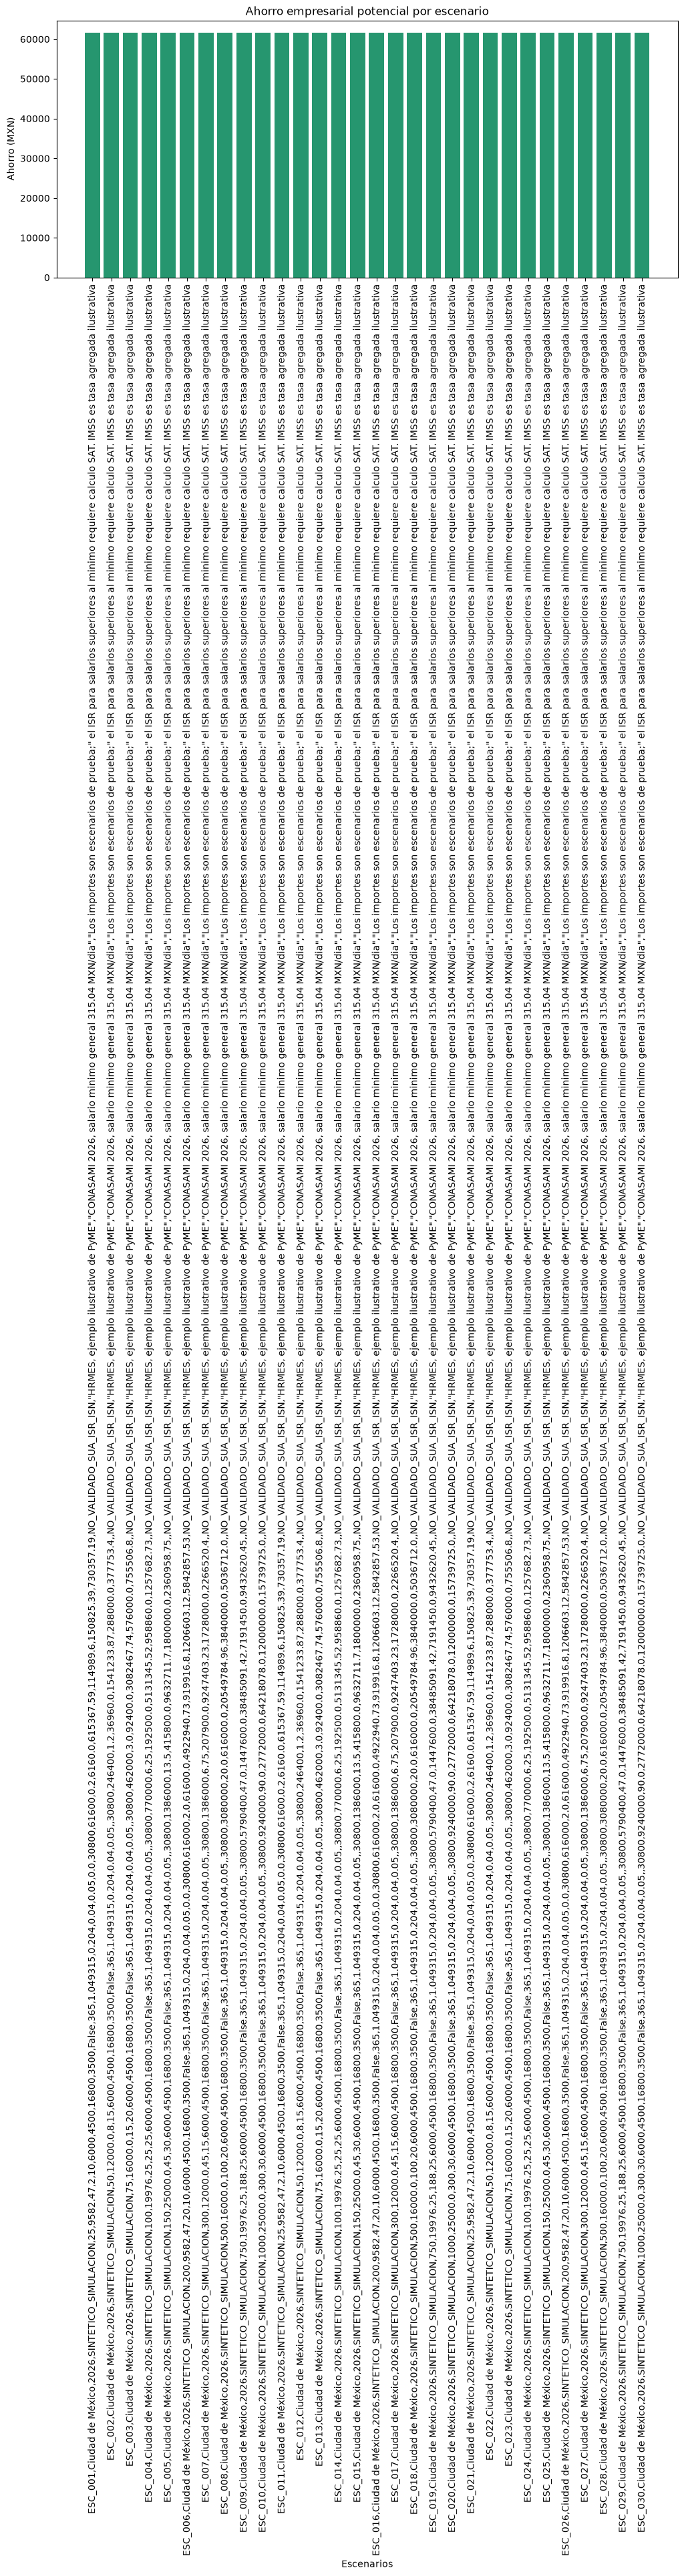

In [28]:
# Guardar gráfica B2B
plt.figure(figsize=(12, 5))

plt.bar(
    df_resultados["escenario_id"],
    df_resultados["ahorro_empresarial"],
    color="#26966F"
)

plt.title("Ahorro empresarial potencial por escenario")
plt.xlabel("Escenarios")
plt.ylabel("Ahorro (MXN)")
plt.xticks(rotation=90)
plt.tight_layout()

plt.savefig("grafica_B2B.png", dpi=300)
plt.show()


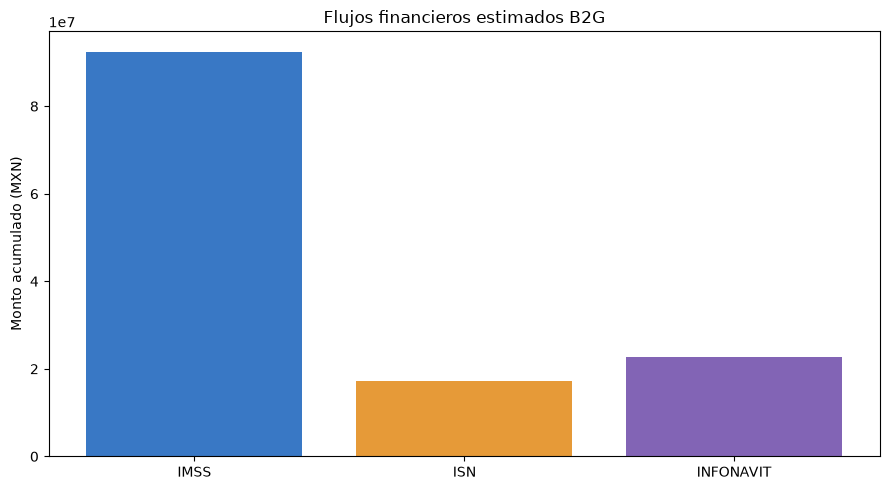

Ambas gráficas fueron guardadas correctamente.


In [29]:
# Guardar gráfica B2G
plt.figure(figsize=(9, 5))

plt.bar(
    ["IMSS", "ISN", "INFONAVIT"],
    [
        df_resultados["imss_estimado"].sum(),
        df_resultados["isn_estimado"].sum(),
        df_resultados["infonavit_separado"].sum()
    ],
    color=["#3978C5", "#E69A38", "#8264B5"]
)

plt.title("Flujos financieros estimados B2G")
plt.ylabel("Monto acumulado (MXN)")
plt.tight_layout()

plt.savefig("grafica_B2G.png", dpi=300)
plt.show()

print("Ambas gráficas fueron guardadas correctamente.")